# Student vectors: friends & field of study

Two vector representations of every student, built **only from course enrollments**, stored in one Qdrant vector database:

| Vector | Question | Method |
|---|---|---|
| `friends` | Who are this student's friends? | MCA on the groups chosen in big multi-group courses |
| `field` | Which of the 7 fields is the student heading to? | Smoothed course→field priors, log-lift sum (updated like a GPA), softmax, √ → unit sphere |

**Input** (set `USE_FAKE_DATA = False` to use your own):
- `enrollments.csv`: `student, course, term, group, credits` (term sortable, e.g. `14031`)
- `fields.csv`: `student, field, declared_term` (only students who already chose a field)

In [1]:
# !pip install pandas numpy scikit-learn prince qdrant-client matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

FIELDS = ["Communications", "RF", "Power", "Electronics", "Bio", "Digital", "Control"]

USE_FAKE_DATA = True          # False -> read your CSV files below
ENROLL_PATH = "enrollments.csv"
FIELDS_PATH = "fields.csv"
DB_PATH = "./student_db"

## 0. Fake data (for testing)

600 students in 4 entry years, split into **known** friend groups of 3–5 who usually pick the same group number in every big course (80% of the time).
Each student has a true field; students take that field's electives with probability 0.6 (others 0.06). Students declare their field in semester 7.
Skip this section when using real data.

In [2]:
def make_fake_data(seed=0, students_per_year=150):
    rng = np.random.default_rng(seed)
    entry_years = [1400, 1401, 1402, 1403]
    term_of = lambda y, sem: (y + sem // 2) * 10 + (sem % 2) + 1
    done_sems = lambda y: (1404 - y) * 2 + 1            # semesters finished by 1404-1

    big = [("Circuits1", 1, 6), ("EngMath", 2, 6), ("Signals", 3, 6), ("Electronics1", 3, 5),
           ("Circuits2", 2, 5), ("Electromagnetics", 4, 6), ("Probability", 3, 5), ("LinearControl", 5, 5)]
    small = [("Physics1", 0), ("Calculus1", 0), ("Physics2", 1), ("Calculus2", 1), ("Programming", 0)]
    electives = {f: [f"{f[:4]}_Elective{i}" for i in range(1, 4)] for f in FIELDS}
    declare_sem = 6

    rows, frows, trows, sid = [], [], [], 0
    for y in entry_years:
        done, left, gid = done_sems(y), students_per_year, 0
        while left > 0:
            size = min(left, rng.integers(3, 6))
            gfield = rng.choice(FIELDS)
            chosen = {c: rng.integers(1, n + 1) for c, _, n in big}
            for _ in range(size):
                s = f"S{sid:04d}"; sid += 1
                field = gfield if rng.random() < 0.5 else rng.choice(FIELDS)
                trows.append((s, f"{y}-{gid}", field, y))
                for c, sem in small:
                    if sem < done: rows.append((s, c, term_of(y, sem), 1, 3))
                for c, sem, n in big:
                    if sem < done:
                        g = chosen[c] if rng.random() < 0.8 else rng.integers(1, n + 1)
                        rows.append((s, c, term_of(y, sem), g, 3))
                for f2, cs in electives.items():
                    for c in cs:
                        if rng.random() < (0.6 if f2 == field else 0.06):
                            sem = rng.integers(5, 8)
                            if sem < done: rows.append((s, c, term_of(y, sem), 1, 3))
                if declare_sem < done:
                    frows.append((s, field, term_of(y, declare_sem)))
            left -= size; gid += 1

    enr = pd.DataFrame(rows, columns=["student", "course", "term", "group", "credits"])
    fields = pd.DataFrame(frows, columns=["student", "field", "declared_term"])
    truth = pd.DataFrame(trows, columns=["student", "true_group", "true_field", "entry_year"]).set_index("student")
    return enr, fields, truth

## 1. Load data

In [3]:
if USE_FAKE_DATA:
    enr, fields, truth = make_fake_data()
else:
    enr, fields, truth = pd.read_csv(ENROLL_PATH), pd.read_csv(FIELDS_PATH), None
    if "credits" not in enr.columns:
        enr["credits"] = 3

enr["student"] = enr["student"].astype(str)
fields["student"] = fields["student"].astype(str)
assert set(fields["field"]) <= set(FIELDS), set(fields["field"]) - set(FIELDS)

print(f"{enr.student.nunique()} students, {enr.course.nunique()} courses, "
      f"{len(enr)} enrollments, {len(fields)} declared fields")
enr.head()

600 students, 34 courses, 7631 enrollments, 300 declared fields


,student,course,term,group,credits
0,S0000,Physics1,14001,1,3
1,S0000,Calculus1,14001,1,3
2,S0000,Physics2,14002,1,3
3,S0000,Calculus2,14002,1,3
4,S0000,Programming,14001,1,3


## 2. Friends vectors

**Step 1 – pick the courses.** Only courses with many groups per term (a real choice, default ≥ 5) that most students took (default ≥ 50%).
Few dimensions, few NULLs.

In [4]:
MIN_GROUPS, MIN_COVERAGE = 5, 0.5

avg_groups = enr.groupby(["course", "term"])["group"].nunique().groupby("course").mean()
coverage = enr.groupby("course")["student"].nunique() / enr["student"].nunique()
summary = pd.DataFrame({"avg_groups": avg_groups, "coverage": coverage}).sort_values("avg_groups", ascending=False)
courses = sorted(summary[(summary.avg_groups >= MIN_GROUPS) & (summary.coverage >= MIN_COVERAGE)].index)

print("selected:", courses)
summary.head(12)

selected: ['Circuits1', 'Circuits2', 'Electromagnetics', 'Electronics1', 'EngMath', 'LinearControl', 'Probability', 'Signals']


,avg_groups,coverage
course,,
Signals,6.0,0.750000
Circuits1,6.0,1.000000
EngMath,6.0,1.000000
Electromagnetics,6.0,0.750000
Electronics1,5.0,0.750000
Circuits2,5.0,1.000000
LinearControl,5.0,0.500000
Probability,5.0,0.750000
Bio_Elective2,1.0,0.060000


**Step 2 – one categorical column per course.** Value = `term_group` (group g2 in 1402 ≠ group g2 in 1403), or `NULL` if the student didn't take it.
Retakes keep the latest attempt.

In [5]:
e = enr[enr["course"].isin(courses)].copy()
e["term_group"] = e["term"].astype(str) + "_g" + e["group"].astype(str)
wide = (e.sort_values("term")
          .pivot_table(index="student", columns="course", values="term_group", aggfunc="last")
          .reindex(sorted(enr["student"].unique()))
          .fillna("NULL"))
wide.head()

course,Circuits1,Circuits2,Electromagnetics,Electronics1,EngMath,LinearControl,Probability,Signals
student,,,,,,,,
S0000,14002_g4,14011_g1,14021_g1,14012_g4,14011_g2,14022_g5,14012_g1,14012_g4
S0001,14002_g4,14011_g1,14021_g1,14012_g1,14011_g2,14022_g5,14012_g2,14012_g2
S0002,14002_g4,14011_g1,14021_g4,14012_g1,14011_g6,14022_g5,14012_g1,14012_g2
S0003,14002_g4,14011_g1,14021_g1,14012_g4,14011_g2,14022_g5,14012_g1,14012_g2
S0004,14002_g4,14011_g2,14021_g1,14012_g1,14011_g4,14022_g5,14012_g1,14012_g2


**Step 3 – MCA (PCA for categorical data).** Groups chosen by the same students land close; groups never chosen together
(e.g. time clashes) are pushed apart, so the gaps fall between clusters. Each student gets a `K`-dim vector, normalized to unit length.

In [6]:
import prince

K = 16
mca = prince.MCA(n_components=K, random_state=0).fit(wide)
F = mca.row_coordinates(wide)
F = F.div(np.linalg.norm(F.values, axis=1), axis=0)          # unit length -> cosine
group_coords = mca.column_coordinates(wide)                    # coordinates of every group (incl. NULL)
F.shape

(600, 16)

**Step 4 – friend groups** with HDBSCAN (label `-1` = no clear group).

83 groups, 138 students unassigned


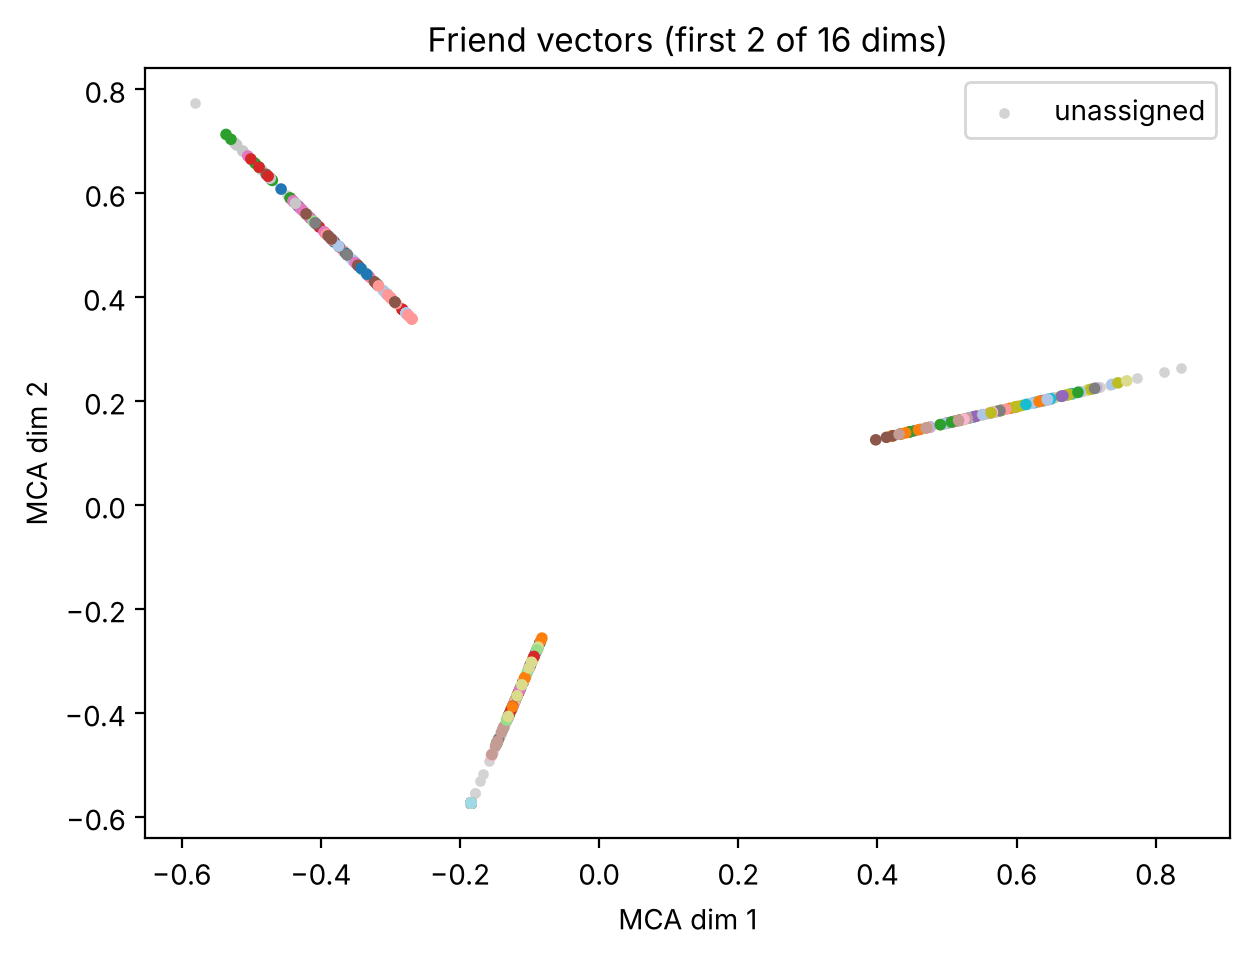

In [7]:
from sklearn.cluster import HDBSCAN

friend_group = pd.Series(HDBSCAN(min_cluster_size=3, copy=True).fit_predict(F.values),
                         index=F.index, name="friend_group")
print(f"{friend_group.max() + 1} groups, {(friend_group == -1).sum()} students unassigned")

fig, ax = plt.subplots(figsize=(7, 5))
m = friend_group != -1
ax.scatter(F.values[~m, 0], F.values[~m, 1], s=8, c="lightgray", label="unassigned")
ax.scatter(F.values[m, 0], F.values[m, 1], s=10, c=friend_group[m] % 20, cmap="tab20")
ax.set_xlabel("MCA dim 1"); ax.set_ylabel("MCA dim 2"); ax.set_title("Friend vectors (first 2 of %d dims)" % K)
ax.legend(loc="upper right"); plt.show()

## 3. Field vectors

For each course *c* and field *f*, using only students who have **already declared**:

$$p_c(f) = \frac{n_{c,f} + m\,\pi_f}{n_c + m} \qquad \text{lift}_c(f) = \log\frac{p_c(f)}{\pi_f}$$

- $\pi_f$ = overall share of field *f*; $m$ pulls small classes toward $\pi$ (smoothing).
- Mandatory courses → lift ≈ 0 (they add nothing); telling electives → big lift.

Student score (updated like a GPA after every course, $w_c$ = credits/3):

$$s(f) = \log \pi_f + \alpha \sum_c w_c\,\text{lift}_c(f), \qquad P = \text{softmax}(s), \qquad v = \sqrt{P}$$

$\|\sqrt{P}\| = 1$, so $v$ sits on the positive part of the 7D unit sphere, and cosine similarity = Bhattacharyya coefficient.

In [8]:
class FieldModel:
    def __init__(self, m=20.0, alpha=0.5):
        self.m, self.alpha = m, alpha

    def fit(self, enr, fields):
        declared = fields.set_index("student")["field"]
        e = enr[enr.student.isin(declared.index)].drop_duplicates(["student", "course"])
        e = e.assign(field=e.student.map(declared))
        counts = declared.value_counts().reindex(FIELDS, fill_value=0).values.astype(float)
        self.pi = (counts + 1) / (counts.sum() + len(FIELDS))
        ct = pd.crosstab(e.course, e.field).reindex(columns=FIELDS, fill_value=0)
        p = (ct.values + self.m * self.pi) / (ct.sum(axis=1).values[:, None] + self.m)
        self.course_p = pd.DataFrame(p, index=ct.index, columns=FIELDS)
        self.lift = pd.DataFrame(np.log(p / self.pi), index=ct.index, columns=FIELDS)
        return self

    def scores(self, enr, students=None):
        e = enr.drop_duplicates(["student", "course"])
        if students is not None:
            e = e[e.student.isin(students)]
        e = e[e.course.isin(self.lift.index)]                     # unseen courses add nothing
        w = (e.credits.values / 3.0)[:, None]
        s = pd.DataFrame(w * self.lift.loc[e.course].values, index=e.student.values, columns=FIELDS)
        s = s.groupby(level=0).sum() * self.alpha + np.log(self.pi)
        idx = sorted(set(enr.student) if students is None else set(students))
        return s.reindex(idx).fillna(pd.Series(np.log(self.pi), index=FIELDS))

    def probabilities(self, enr, students=None):
        s = self.scores(enr, students).values
        z = np.exp(s - s.max(axis=1, keepdims=True))
        return pd.DataFrame(z / z.sum(axis=1, keepdims=True),
                            index=self.scores(enr, students).index, columns=FIELDS)

    def vectors(self, enr, students=None):
        return np.sqrt(self.probabilities(enr, students))

    def update(self, score, course, credits=3):
        """GPA-style: add one finished course to a student's score."""
        if course in self.lift.index:
            score = score + self.alpha * credits / 3.0 * self.lift.loc[course].values
        return score

**Choosing α without leakage:** learn the course priors only from students declared **before** the latest term,
predict the students who declared **in** it, using only courses they took before declaring. Keep the α with the lowest log-loss.

In [9]:
def evaluate(enr, fields, test_term, alpha, m=20.0):
    model = FieldModel(m, alpha).fit(enr, fields[fields.declared_term < test_term])
    test = fields[fields.declared_term == test_term]
    e = enr.merge(test[["student", "declared_term"]], on="student")
    e = e[e.term < e.declared_term]
    P = model.probabilities(e, students=test.student)
    truth_f = test.set_index("student").field.reindex(P.index)
    p_true = P.values[np.arange(len(P)), [FIELDS.index(t) for t in truth_f]]
    top2 = P.apply(lambda r: set(r.nlargest(2).index), axis=1)
    return dict(alpha=alpha, n=len(P),
                accuracy=(P.idxmax(axis=1) == truth_f).mean(),
                top2=np.mean([t in s for t, s in zip(truth_f, top2)]),
                log_loss=-np.log(p_true + 1e-12).mean())

test_term = fields.declared_term.max()
tuning = pd.DataFrame([evaluate(enr, fields, test_term, a) for a in [0.1, 0.2, 0.3, 0.5, 0.75, 1, 1.5, 2, 3]])
ALPHA = tuning.loc[tuning.log_loss.idxmin(), "alpha"]
print("chosen alpha =", ALPHA)
tuning.round(3)

chosen alpha = 1.5


,alpha,n,accuracy,top2,log_loss
0,0.10,150,0.273,0.407,1.893
1,0.20,150,0.347,0.500,1.839
2,0.30,150,0.400,0.553,1.788
3,0.50,150,0.433,0.567,1.700
4,0.75,150,0.440,0.567,1.617
5,1.00,150,0.440,0.567,1.562
6,1.50,150,0.440,0.567,1.524
7,2.00,150,0.433,0.567,1.554
8,3.00,150,0.433,0.560,1.733


Fit on **all** declarations and compute every student's field vector.

In [10]:
field_model = FieldModel(alpha=ALPHA).fit(enr, fields)
V = field_model.vectors(enr)          # √P, unit length
P = V ** 2                            # back to probabilities

print("all norms = 1:", np.allclose(np.linalg.norm(V.values, axis=1), 1))
print("\nmost telling courses per field (highest lift):")
for f in FIELDS:
    print(f"  {f:15s}", ", ".join(field_model.lift[f].nlargest(3).index))

all norms = 1: True

most telling courses per field (highest lift):
  Communications  Comm_Elective2, Comm_Elective1, Comm_Elective3
  RF              RF_Elective3, RF_Elective1, RF_Elective2
  Power           Powe_Elective2, Powe_Elective3, Powe_Elective1
  Electronics     Elec_Elective1, Elec_Elective3, Elec_Elective2
  Bio             Bio_Elective1, Bio_Elective2, Bio_Elective3
  Digital         Digi_Elective3, Digi_Elective2, Digi_Elective1
  Control         Cont_Elective1, Cont_Elective3, Cont_Elective2


**GPA-style update** – watch one student's attitude change course by course:

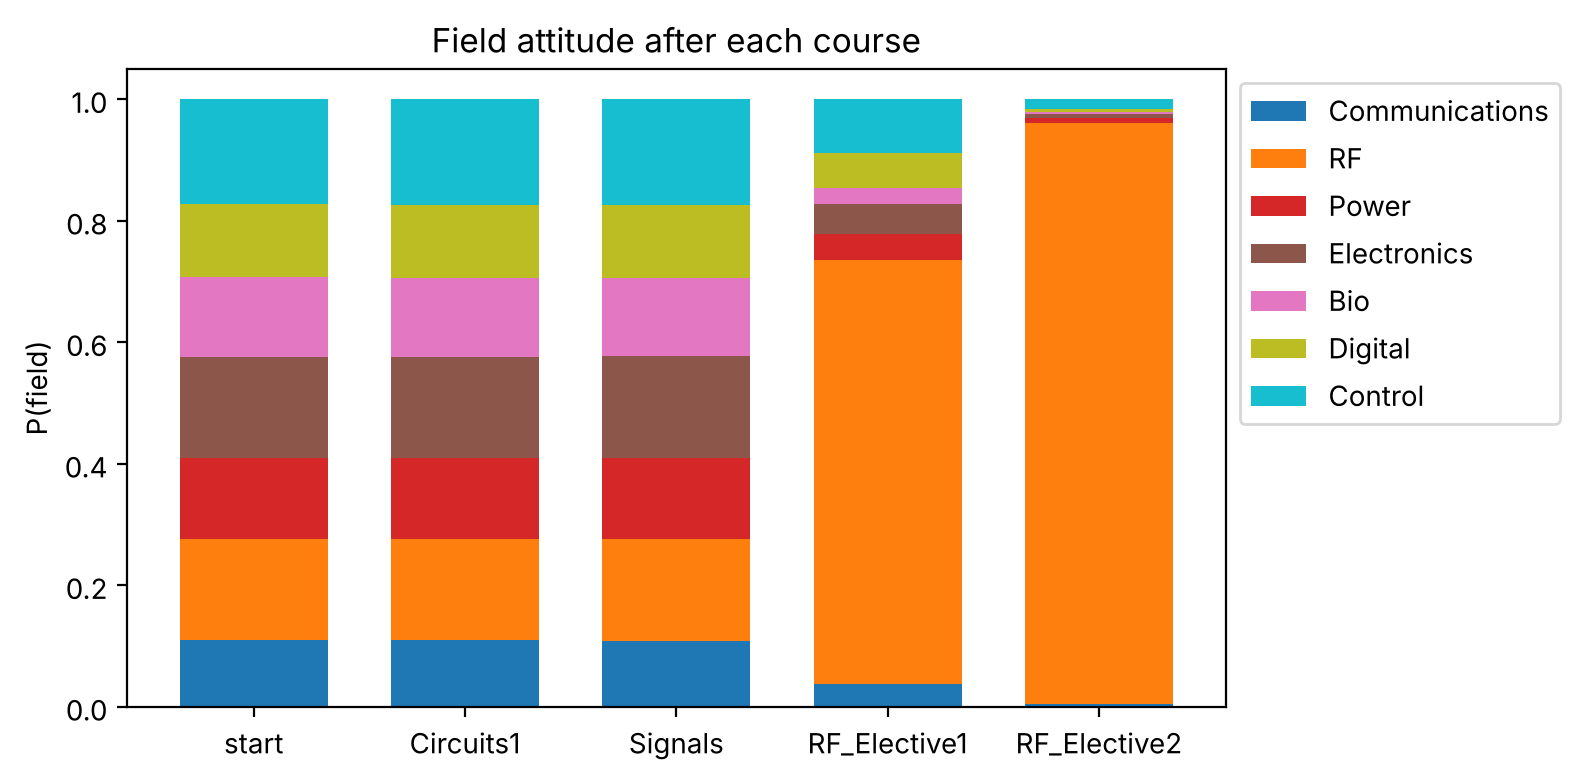

,Communications,RF,Power,Electronics,Bio,Digital,Control
start,0.11,0.17,0.13,0.17,0.13,0.12,0.17
Circuits1,0.11,0.17,0.13,0.17,0.13,0.12,0.17
Signals,0.11,0.17,0.13,0.17,0.13,0.12,0.17
RF_Elective1,0.04,0.70,0.04,0.05,0.03,0.06,0.09
RF_Elective2,0.01,0.96,0.01,0.01,0.00,0.01,0.02


In [11]:
score = np.log(field_model.pi)
history = {"start": score}
for course in ["Circuits1", "Signals", "RF_Elective1", "RF_Elective2"]:
    score = field_model.update(score, course, credits=3)
    history[course] = score

H = pd.DataFrame({k: np.exp(v - v.max()) / np.exp(v - v.max()).sum() for k, v in history.items()},
                 index=FIELDS).T
H.plot(kind="bar", stacked=True, figsize=(8, 4), colormap="tab10", width=0.7)
plt.ylabel("P(field)"); plt.title("Field attitude after each course"); plt.legend(bbox_to_anchor=(1, 1))
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
H.round(2)

## 4. Vector database (Qdrant)

One point per student with **two named vectors**: `friends` (K dims) and `field` (7 dims), both cosine.
Payload: student id, predicted field, field probabilities, declared field (if any), friend group.

In [12]:
from qdrant_client import QdrantClient
from qdrant_client.models import VectorParams, Distance, PointStruct, Filter, FieldCondition, MatchValue

try:
    client.close()                                # allows re-running this cell (local DB is locked while open)
except NameError:
    pass
client = QdrantClient(path=DB_PATH)               # or QdrantClient(":memory:")
COLL = "students"
if client.collection_exists(COLL):
    client.delete_collection(COLL)
client.create_collection(COLL, vectors_config={
    "friends": VectorParams(size=F.shape[1], distance=Distance.COSINE),
    "field":   VectorParams(size=len(FIELDS), distance=Distance.COSINE),
})

declared = fields.set_index("student").field
points = []
for i, sid in enumerate(F.index):
    payload = {"student": sid,
               "predicted_field": P.loc[sid].idxmax(),
               "field_probs": P.loc[sid].round(4).to_dict(),
               "friend_group": int(friend_group[sid])}
    if sid in declared.index:
        payload["declared_field"] = declared[sid]
    points.append(PointStruct(id=i, payload=payload,
                              vector={"friends": F.loc[sid].tolist(), "field": V.loc[sid].tolist()}))
for j in range(0, len(points), 512):
    client.upsert(COLL, points=points[j:j + 512])

print("stored:", client.count(COLL).count)

stored: 600


In [13]:
def find_similar(student, using="friends", k=5):
    pts, _ = client.scroll(COLL, with_vectors=True, limit=1, scroll_filter=Filter(
        must=[FieldCondition(key="student", match=MatchValue(value=str(student)))]))
    p = pts[0]
    hits = client.query_points(COLL, query=p.vector[using], using=using, limit=k + 1, with_payload=True).points
    return pd.DataFrame([{"student": h.payload["student"], "score": round(h.score, 4),
                          "predicted_field": h.payload["predicted_field"]}
                         for h in hits if h.id != p.id][:k])

STUDENT = F.index[10]
print("likely friends of", STUDENT)
display(find_similar(STUDENT, "friends"))
print("most similar field attitude to", STUDENT)
display(find_similar(STUDENT, "field"))

likely friends of S0010


,student,score,predicted_field
0,S0127,0.9675,Control
1,S0063,0.9668,Communications
2,S0008,0.9516,Control
3,S0033,0.9508,Electronics
4,S0117,0.9508,Communications


most similar field attitude to S0010


,student,score,predicted_field
0,S0107,1.0000,Power
1,S0132,0.9993,Power
2,S0193,0.9993,Power
3,S0264,0.9993,Power
4,S0028,0.9982,Power


## 5. Check against the truth (fake data only)

- **precision@3**: share of each student's 3 nearest neighbours that are real friends.
- **ARI**: agreement between HDBSCAN groups and real groups (1 = perfect, 0 = random).
- **Field accuracy** for undeclared students, by entry year.

In [14]:
if truth is not None:
    from sklearn.metrics import adjusted_rand_score
    tg = truth.loc[F.index, "true_group"].to_numpy(dtype=object)
    sim = F.values @ F.values.T
    np.fill_diagonal(sim, -np.inf)
    nn = np.argsort(-sim, axis=1)[:, :3]
    print(f"friends  precision@3 = {(tg[nn] == tg[:, None]).mean():.3f}   (random ≈ {3.75/599:.3f})")
    m = friend_group.values != -1
    print(f"friends  ARI = {adjusted_rand_score(tg[m], friend_group.values[m]):.3f} on {m.mean():.0%} of students")

    und = P[~P.index.isin(declared.index)].idxmax(axis=1).rename("pred").to_frame().join(truth)
    print(f"field    accuracy on undeclared = {(und.pred == und.true_field).mean():.3f}   (random = {1/7:.3f})")
    display(und.groupby("entry_year").apply(lambda d: (d.pred == d.true_field).mean()).rename("accuracy"))

friends  precision@3 = 0.440   (random ≈ 0.006)
friends  ARI = 0.415 on 77% of students
field    accuracy on undeclared = 0.133   (random = 0.143)


entry_year
1402    0.146667
1403    0.120000
Name: accuracy, dtype: float64

> **Note on the field result:** in the fake data, undeclared students (entry years 1402–1403) haven't taken any electives yet,
> and mandatory courses have lift ≈ 0, so their prediction stays near the overall average. That's expected: the model only becomes
> confident once a student starts picking electives.

## 6. Export

In [15]:
out = pd.concat([friend_group, P.add_prefix("p_"), P.idxmax(axis=1).rename("predicted_field"),
                 declared.rename("declared_field")], axis=1)
out.index.name = "student"
out.to_csv("results.csv")
out.head()

,friend_group,p_Communications,p_RF,p_Power,p_Electronics,p_Bio,p_Digital,p_Control,predicted_field,declared_field
student,,,,,,,,,,
S0000,74,0.039028,0.666995,0.060951,0.070349,0.044654,0.028478,0.089545,RF,Electronics
S0001,75,0.380444,0.378546,0.017050,0.172246,0.027562,0.016584,0.007568,Communications,Communications
S0002,-1,0.066490,0.101092,0.051093,0.339926,0.038034,0.320442,0.082924,Electronics,Digital
S0003,74,0.001819,0.000257,0.000102,0.000333,0.000150,0.000616,0.996723,Control,Control
S0004,-1,0.013234,0.430863,0.242552,0.210847,0.011635,0.038653,0.052215,RF,Power
